# 곁(GYEOT) 고령자 이상거래 탐지 v2

**한 줄 결론**: 라벨로 학습한 모델은 아는 사기를 잘 잡지만, 처음 보는 유형은 0%다. 그래서 알림을 **지도학습 트랙 + 비지도 트랙** 두 갈래로 나누는 구조를 제안하고, 예산 배분을 숫자로 정한다.

v1 대비 바뀐 점:

1. 재무 시뮬레이션 제외, 탐지에 집중
2. **수취인 추세 피처** 추가 (서서히 늘어나는 착취 대응)
3. **스태킹**: Isolation Forest 점수를 부스팅의 입력으로
4. **처음 보는 사기 실험**: 한 유형의 라벨을 빼고 학습해 일반화 능력 측정
5. **2트랙 알림 설계**: 알림 예산을 두 모델에 나눠 배분
6. **실제 발생률 기준 정밀도**: 사기를 부풀린 데이터의 정밀도를 현실 비율로 보정
7. **알림 사유**: 자녀에게 보낼 문구로 판단 근거 제시

주의: 직접 설계한 가상 데이터다. 탐지율의 절대값보다 **모델 간 비교, 실험 설계, 평가 기준**에 의미가 있다.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib import font_manager
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import average_precision_score
from sklearn.inspection import permutation_importance

for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.dpi"] = 110
GREY, DARK, BLUE, RED = "#b0b4b8", "#5f6368", "#1a73e8", "#d93025"
SC_KO = {"impersonation": "사칭 송금", "cash_pickup": "대면편취(현금)", "loan_scam": "대출사기", "exploitation": "주변인 착취"}

def clean(ax):
    ax.spines[["top", "right"]].set_visible(False)

## 1. 가상 거래 데이터

| 구분 | 내용 |
| --- | --- |
| 평소 패턴 | 월 연금 입금, 공과금 3건, ATM 인출 월 2.5회, 지인 송금 월 1.5회, 카드 하루 0.5건. 개인마다 소득 규모가 다름 |
| 정상이지만 튀는 거래 | 병원비 큰 결제, 경조사(새 계좌 송금), 자녀에게 큰 돈, 이사·수리(새 계좌 큰 송금), 명절 현금 여러 번 인출, 정상 대출(2%) |
| 사칭 송금 | 새 계좌로 몇 시간 안에 1~3회 송금, 금액 편차 큼 |
| 대면편취(현금) | 1~3일 사이 현금 2~5회 인출 |
| 대출사기 | 비대면 대출 입금 → 하루 안에 새 계좌 이체 또는 현금 인출 |
| 주변인 착취 | 매주 중간 금액 송금이 수개월. 절반은 **이미 알던 수취인** |

사기는 가구의 6%에 주입했다(학습·평가 사례 확보용). 7장에서 실제 발생률로 보정한다.

In [2]:
"""가상 고령자 거래 데이터 생성기 (곁 GYEOT 이상거래 탐지용)

- 개인마다 '평소 패턴'(연금 입금, 공과금, 카드, ATM 인출, 지인 송금)을 따로 갖는다.
- 정상이지만 튀는 거래(병원비, 경조사 송금, 자녀 증여)를 섞어 오탐 상황을 만든다.
- 일부 개인에게 사기/착취 에피소드를 주입하고 거래 단위 라벨(is_fraud)과 episode_id를 붙인다.
"""
import numpy as np
import pandas as pd

TYPES = ["pension_in", "bill", "card", "atm", "transfer_out", "loan_in"]


def generate(n_people=1500, days=365, fraud_rate=0.06, seed=42):
    rng = np.random.default_rng(seed)
    start = pd.Timestamp("2025-01-01")
    rows = []
    ep_meta = []
    ep_id = 0

    def add(pid, t, typ, amt, payee, fraud=0, ep=-1):
        rows.append((pid, t, typ, float(round(amt, -2)), payee, fraud, ep))

    for pid in range(n_people):
        # 개인 특성: 소득·지출 규모
        wealth = rng.lognormal(0, 0.5)
        pension = 900_000 * wealth
        card_mu = np.log(25_000 * wealth)
        atm_mu = np.log(200_000 * wealth)
        tr_mu = np.log(150_000 * wealth)
        known = [f"P{pid}_k{i}" for i in range(rng.integers(2, 5))]
        active_h = rng.integers(8, 11)  # 주로 활동 시작 시각

        def ts(day, night=False):
            h = rng.integers(0, 6) if night else int(np.clip(rng.normal(active_h + 4, 3), 6, 21))
            return start + pd.Timedelta(days=int(day), hours=int(h), minutes=int(rng.integers(0, 60)))

        for m in range(12):
            d0 = m * 30
            add(pid, ts(d0 + 24), "pension_in", pension, "NPS")
            for b in range(3):  # 공과금·통신비·보험료
                add(pid, ts(d0 + 10 + b * 5), "bill", 60_000 * wealth * rng.uniform(0.6, 1.4), f"BILL{b}")
            for _ in range(rng.poisson(2.5)):
                add(pid, ts(d0 + rng.integers(0, 30)), "atm", rng.lognormal(atm_mu, 0.4), "ATM")
            for _ in range(rng.poisson(1.5)):
                add(pid, ts(d0 + rng.integers(0, 30)), "transfer_out", rng.lognormal(tr_mu, 0.6), rng.choice(known))
        for d in range(days):
            for _ in range(rng.poisson(0.5)):
                add(pid, ts(d), "card", rng.lognormal(card_mu, 0.8), f"M{rng.integers(0, 300)}")

        # 정상이지만 튀는 거래 (오탐 유발): 사기와 겉모습이 비슷한 진짜 거래
        for _ in range(rng.poisson(3)):
            kind = rng.choice(["hospital", "gift", "family", "big_new", "holiday_cash"],
                              p=[0.2, 0.25, 0.2, 0.15, 0.2])
            d = int(rng.integers(20, days - 3))
            if kind == "hospital":
                add(pid, ts(d), "card", rng.lognormal(np.log(1_500_000 * wealth), 0.5), "HOSP")
            elif kind == "gift":  # 경조사: 처음 보는 계좌로 송금
                add(pid, ts(d), "transfer_out", rng.choice([100_000, 200_000, 300_000, 500_000]), f"P{pid}_g{d}")
            elif kind == "family":  # 자녀에게 큰 돈
                add(pid, ts(d), "transfer_out", rng.lognormal(np.log(3_000_000 * wealth), 0.6), known[0])
            elif kind == "big_new":  # 이사·수리·중고거래: 처음 보는 계좌로 큰 돈
                add(pid, ts(d), "transfer_out", rng.lognormal(np.log(2_000_000 * wealth), 0.7), f"P{pid}_n{d}")
            else:  # 명절·경조사 현금: 이틀 동안 여러 번 인출
                for k in range(rng.integers(2, 4)):
                    add(pid, ts(d + k // 2), "atm", rng.lognormal(np.log(600_000 * wealth), 0.4), "ATM")
        if rng.random() < 0.02:  # 정상 대출 후 자녀에게 이체
            d = int(rng.integers(30, days - 2))
            loan = rng.choice([5_000_000, 10_000_000, 30_000_000])
            add(pid, ts(d), "loan_in", loan, "LOAN")
            add(pid, ts(d + 1), "transfer_out", loan * rng.uniform(0.5, 1.0), known[0])

        # 사기/착취 에피소드 주입 (4~12개월 사이)
        if rng.random() < fraud_rate:
            sc = rng.choice(["impersonation", "cash_pickup", "loan_scam", "exploitation"],
                            p=[0.35, 0.25, 0.2, 0.2])
            d = int(rng.integers(100, days - 40))
            ep_id += 1
            total = 0.0
            if sc == "impersonation":  # 가족·기관 사칭: 새 계좌로 몇 시간 안에 연속 송금 (금액 편차 큼)
                t0 = ts(d)
                for k in range(rng.integers(1, 4)):
                    a = rng.lognormal(np.log(2_500_000 * wealth), 0.9)
                    add(pid, t0 + pd.Timedelta(minutes=int(40 * k)), "transfer_out", a, f"F{ep_id}", 1, ep_id)
                    total += a
            elif sc == "cash_pickup":  # 대면편취: 1~3일 사이 현금 여러 번 인출
                for k in range(rng.integers(2, 6)):
                    a = rng.lognormal(np.log(700_000 * wealth), 0.5)
                    add(pid, ts(d + k // 2), "atm", a, "ATM", 1, ep_id)
                    total += a
            elif sc == "loan_scam":  # 비대면 대출 실행 → 하루 안에 새 계좌 이체 또는 현금 인출
                loan = rng.choice([5_000_000, 10_000_000, 20_000_000])
                t0 = ts(d)
                add(pid, t0, "loan_in", loan, "LOAN", 1, ep_id)
                if rng.random() < 0.5:
                    a = loan * rng.uniform(0.9, 1.0)
                    add(pid, t0 + pd.Timedelta(hours=int(rng.integers(1, 20))), "transfer_out", a, f"F{ep_id}", 1, ep_id)
                    total += a
                else:
                    for k in range(rng.integers(2, 5)):
                        a = rng.lognormal(np.log(1_000_000), 0.3)
                        add(pid, t0 + pd.Timedelta(hours=int(2 + 3 * k)), "atm", a, "ATM", 1, ep_id)
                        total += a
            else:  # 주변인 착취: 매주 중간 금액, 수개월. 절반은 이미 알던 수취인
                payee = f"F{ep_id}" if rng.random() < 0.5 else known[-1]
                for k in range(rng.integers(6, 14)):
                    a = rng.lognormal(np.log(250_000 * wealth), 0.4)
                    add(pid, ts(min(d + 7 * k, days - 1)), "transfer_out", a, payee, 1, ep_id)
                    total += a
            ep_meta.append((ep_id, pid, sc, total))

    df = pd.DataFrame(rows, columns=["pid", "ts", "type", "amount", "payee", "is_fraud", "episode"])
    df = df.sort_values(["pid", "ts"]).reset_index(drop=True)
    eps = pd.DataFrame(ep_meta, columns=["episode", "pid", "scenario", "loss"])
    return df, eps




In [3]:
df_raw, eps = generate(n_people=4000, seed=42)
print(f"거래 {len(df_raw):,}건, 가구 {df_raw.pid.nunique():,}, 사기 에피소드 {len(eps)}개")
eps.scenario.map(SC_KO).value_counts().rename("에피소드 수").to_frame().T

거래 1,130,613건, 가구 4,000, 사기 에피소드 244개


scenario,사칭 송금,대면편취(현금),대출사기,주변인 착취
에피소드 수,82,58,56,48


## 2. 피처: '그 사람의 평소'와 비교

모든 피처는 **그 거래 이전 정보만** 쓴다. 기준은 절대 금액이 아니라 개인의 평소다.

| 피처 | 의미 | 노리는 사기 |
| --- | --- | --- |
| `z_type` | 같은 유형 과거 거래 대비 금액 z-score | 전반 |
| `new_payee`, `payee_cnt_30d` | 처음 보는 수취인, 최근 30일 같은 수취인 송금 횟수 | 사칭 |
| `n_out_24h`, `out_24h_ratio` | 직전 24시간 출금 건수, 평소 하루 출금 대비 배율 | 대면편취 |
| `out_30d_ratio` | 최근 30일 출금이 평소 한 달의 몇 배인지 | 착취 |
| `loan_48h` | 48시간 안에 대출 입금 | 대출사기 |
| **`payee_trend`** (v2) | 이 수취인에게 최근 28일 보낸 돈 ÷ 그 전 28일 | 착취 |
| **`payee_28d_ratio`** (v2) | 이 수취인 몫이 평소 한 달 지출의 몇 배인지 | 착취 |
| **`payee_cnt_90d`** (v2) | 최근 90일 같은 수취인 송금 횟수 | 착취 |

In [4]:
"""거래 단위 피처 생성. 모든 피처는 '그 거래 이전' 정보만 사용한다(누수 방지)."""
import numpy as np
import pandas as pd

OUT_TYPES = ["card", "atm", "transfer_out", "bill"]


def _window(keys, ts, vals, window_sec):
    """같은 key 그룹 안에서, 현재 행 '이전' 행들 중 [t-window, t] 구간의 vals 합 (현재 행 제외)."""
    order = np.lexsort((np.arange(len(ts)), ts, keys))
    k = keys[order].astype(np.int64)
    t = ts[order]
    v = vals[order].astype(float)
    comp = k * 10**9 + t
    left = np.searchsorted(comp, comp - window_sec, side="left")
    cs = np.concatenate([[0.0], np.cumsum(v)])
    pos = np.arange(len(t))
    res = cs[pos] - cs[left]
    out = np.empty(len(t))
    out[order] = res
    return out


def build_features(df):
    df = df.sort_values(["pid", "ts"]).reset_index(drop=True).copy()
    df["log_amt"] = np.log1p(df["amount"])
    df["is_out"] = df["type"].isin(OUT_TYPES).astype(int)
    df["out_amt"] = df["amount"] * df["is_out"]
    df["is_loan"] = (df["type"] == "loan_in").astype(int)
    df["hour"] = df["ts"].dt.hour
    df["night"] = (df["hour"] < 6).astype(int)

    # 1) 같은 유형 거래 대비 평소와 얼마나 다른가 (개인별 z-score)
    g = df.groupby(["pid", "type"])["log_amt"]
    df["past_mean"] = g.transform(lambda s: s.shift().expanding().mean())
    df["past_std"] = g.transform(lambda s: s.shift().expanding().std())
    df["past_n"] = df.groupby(["pid", "type"]).cumcount()
    df["z_type"] = (df["log_amt"] - df["past_mean"]) / df["past_std"].clip(lower=0.3)
    df["z_type"] = df["z_type"].where(df["past_n"] >= 3, 0.0).fillna(0.0)

    # 2) 처음 보는 수취인 / 최근 30일 그 수취인에게 보낸 횟수
    tr = df["type"] == "transfer_out"
    first_seen = df.groupby(["pid", "payee"]).cumcount() == 0
    df["new_payee"] = (first_seen & tr).astype(int)
    sec = ((df["ts"] - pd.Timestamp("2025-01-01")).dt.total_seconds()).to_numpy().astype(np.int64)
    pid = df["pid"].to_numpy()
    payee_key = df.groupby(["pid", "payee"]).ngroup().to_numpy()
    ones = np.ones(len(df))
    df["payee_cnt_30d"] = _window(payee_key, sec, ones, 30 * 86400) * tr

    # 3) 시간 창 집계: 직전 24시간 출금 건수·금액, 48시간 내 대출 입금, 30일 출금 합
    df["n_out_24h"] = _window(pid, sec, df["is_out"].to_numpy(), 86400)
    df["sum_out_24h"] = _window(pid, sec, df["out_amt"].to_numpy(), 86400) + df["out_amt"]
    df["loan_48h"] = (_window(pid, sec, df["is_loan"].to_numpy(), 2 * 86400) > 0).astype(int)
    df["sum_out_30d"] = _window(pid, sec, df["out_amt"].to_numpy(), 30 * 86400) + df["out_amt"]

    # 4) 수취인 추세 (v2): 이 수취인에게 최근 28일 보낸 돈이 그 이전 28일보다 얼마나 늘었나
    amt_tr = (df["amount"] * tr).to_numpy()
    s28 = _window(payee_key, sec, amt_tr, 28 * 86400)
    s56 = _window(payee_key, sec, amt_tr, 56 * 86400)
    df["payee_28d_amt"] = (s28 + amt_tr) * tr
    df["payee_trend"] = np.log1p((s28 + amt_tr) / (s56 - s28 + 100_000)) * tr
    df["payee_cnt_90d"] = _window(payee_key, sec, ones, 90 * 86400) * tr

    # 평소 하루 출금액 (지금까지 누적 출금 / 경과 일수)
    cum_out = df.groupby("pid")["out_amt"].cumsum() - df["out_amt"]
    days = (df["ts"] - df.groupby("pid")["ts"].transform("min")).dt.total_seconds() / 86400
    daily = (cum_out / days.clip(lower=1)).clip(lower=10_000)
    df["out_24h_ratio"] = df["sum_out_24h"] / daily
    df["out_30d_ratio"] = df["sum_out_30d"] / (daily * 30)
    df["payee_28d_ratio"] = df["payee_28d_amt"] / (daily * 28)   # 이 수취인 몫이 평소 한 달 지출의 몇 배인지

    for t in ["atm", "transfer_out", "card", "loan_in"]:
        df[f"t_{t}"] = (df["type"] == t).astype(int)
    return df


FEATURES_V1 = ["log_amt", "z_type", "new_payee", "payee_cnt_30d", "n_out_24h", "out_24h_ratio",
               "out_30d_ratio", "loan_48h", "t_atm", "t_transfer_out", "t_card", "t_loan_in"]
FEATURES = FEATURES_V1 + ["payee_trend", "payee_28d_ratio", "payee_cnt_90d"]


In [5]:
df = build_features(df_raw)
ev = df[df.ts >= pd.Timestamp("2025-04-01")].copy()   # 첫 3개월은 '평소'를 배우는 기간
ev = ev.merge(eps[["episode", "scenario"]], on="episode", how="left")
print(f"평가 대상 거래 {len(ev):,}건, 사기 거래 비율 {ev.is_fraud.mean():.3%}")

평가 대상 거래 850,958건, 사기 거래 비율 0.118%


## 3. 모델 비교 (가구 단위 5-fold 교차검증)

같은 가구가 학습과 평가에 동시에 들어가지 않게 가구 단위로 fold를 나눈다.

- **규칙(z-score)**: 라벨 없이 쓰는 출발점
- **Isolation Forest**: 비지도. '드문 거래'를 찾는다
- **부스팅**: 지도학습 (HistGradientBoosting, 클래스 가중치 균형)
- **스태킹**: 같은 fold 학습 데이터로 만든 Isolation Forest 점수를 부스팅의 입력 피처로 추가

v1 피처(12개)와 v2 피처(15개)로 각각 돌려 수취인 추세 피처의 효과도 함께 본다.

In [6]:
folds = list(GroupKFold(n_splits=5).split(ev, groups=ev.pid))
HGB = dict(max_iter=300, learning_rate=0.05, class_weight="balanced")

def oof(make_score):
    out = np.full(len(ev), np.nan)
    for k, (a, b) in enumerate(folds):
        out[b] = make_score(ev.iloc[a], ev.iloc[b], k)
    return out

def iso_score(F):
    def f(tr, te, k):
        m = IsolationForest(n_estimators=200, random_state=k).fit(tr[F].sample(200_000, random_state=k))
        return -m.score_samples(te[F])
    return f

def hgb_score(F, exclude=None):
    def f(tr, te, k):
        if exclude: tr = tr[tr.scenario != exclude]
        m = HistGradientBoostingClassifier(random_state=k, **HGB).fit(tr[F], tr.is_fraud)
        return m.predict_proba(te[F])[:, 1]
    return f

ev["s_rule"] = ev.z_type.clip(lower=0) + 2*ev.new_payee + 3*ev.loan_48h + 0.3*np.log1p(ev.out_24h_ratio)
ev["s_iso_v1"] = oof(iso_score(FEATURES_V1))
ev["s_iso"] = oof(iso_score(FEATURES))
ev["s_hgb_v1"] = oof(hgb_score(FEATURES_V1))
ev["s_hgb"] = oof(hgb_score(FEATURES))
# 스태킹: iso 점수는 위에서 fold별 학습 데이터로만 만든 out-of-fold 값이라 누수가 없다
F_STACK = FEATURES + ["s_iso"]
ev["s_stack"] = oof(hgb_score(F_STACK))
MODELS = {"규칙(z-score)": "s_rule", "Isolation Forest": "s_iso", "부스팅": "s_hgb", "스태킹": "s_stack"}
pd.Series({m: average_precision_score(ev.is_fraud, ev[s]) for m, s in MODELS.items()},
          name="PR-AUC (거래 단위)").round(3).to_frame().T

,규칙(z-score),Isolation Forest,부스팅,스태킹
PR-AUC (거래 단위),0.029,0.062,0.354,0.376


> **누수 점검**: 스태킹의 `s_iso`는 학습 fold에 fit한 Isolation Forest로 평가 fold를 채점한 값이다. 그런데 학습 fold 안의 행들은 *다른* fold 모델이 채점한 값이다. 엄밀히는 학습 fold 내부에서 한 번 더 교차검증해야 한다. 다만 Isolation Forest는 라벨을 쓰지 않으므로 라벨 누수는 없다. 이 정도 근사는 실무에서도 흔히 쓴다.

### 평가 기준: 알림 예산

가족에게는 거래 단위 정확도보다 **사기 사건(에피소드)을 한 번이라도 알려줬는지**가 중요하다. 그래서 '가구당 한 달 알림 수'를 예산으로 정해 두고, 점수 상위 거래부터 알림을 보낸다고 가정한다.

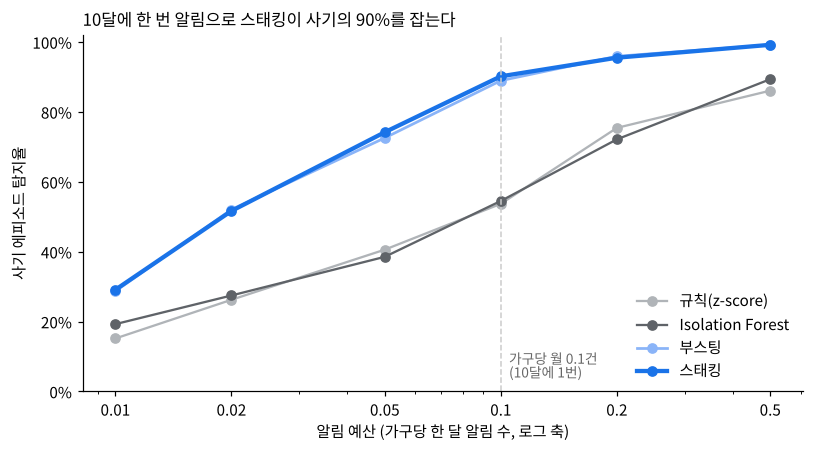

예산,0.01,0.02,0.05,0.10,0.20,0.50
모델,,,,,,
Isolation Forest,0.19,0.27,0.39,0.55,0.72,0.89
규칙(z-score),0.15,0.26,0.41,0.54,0.75,0.86
부스팅,0.29,0.52,0.73,0.89,0.96,0.99
스태킹,0.29,0.52,0.74,0.90,0.95,0.99


In [7]:
N_FAM, MONTHS = ev.pid.nunique(), 9

def alerts(score, budget, frame=None):
    frame = ev if frame is None else frame
    k = max(int(budget * N_FAM * MONTHS), 1)
    return frame.nlargest(k, score)

def recall(al, scen=None):
    e = eps if scen is None else eps[eps.scenario == scen]
    return e.episode.isin(al.loc[al.is_fraud == 1, "episode"]).mean()

budgets = [0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
curve = pd.DataFrame([dict(모델=m, 예산=b, 탐지율=recall(alerts(s, b))) for m, s in MODELS.items() for b in budgets])

fig, ax = plt.subplots(figsize=(7.5, 4.2))
style = {"규칙(z-score)": (GREY, 1.5), "Isolation Forest": (DARK, 1.5), "부스팅": ("#8ab4f8", 1.8), "스태킹": (BLUE, 2.8)}
for m in MODELS:
    c = curve[curve.모델 == m]; col, lw = style[m]
    ax.plot(c.예산, c.탐지율, marker="o", color=col, lw=lw, label=m)
ax.axvline(0.1, color="#ccc", ls="--", lw=1)
ax.text(0.105, 0.04, "가구당 월 0.1건\n(10달에 1번)", color="#666", fontsize=9)
ax.set_xscale("log"); ax.set_xticks(budgets); ax.set_xticklabels([str(b) for b in budgets])
ax.set_ylim(0, 1.02); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.set_xlabel("알림 예산 (가구당 한 달 알림 수, 로그 축)"); ax.set_ylabel("사기 에피소드 탐지율")
r = curve[curve.예산 == 0.1].set_index("모델").탐지율
ax.set_title(f"10달에 한 번 알림으로 스태킹이 사기의 {r['스태킹']:.0%}를 잡는다", loc="left", fontsize=11)
clean(ax); ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()
curve.pivot(index="모델", columns="예산", values="탐지율").round(2)

### 유형별 탐지율, 그리고 v2 피처의 효과 (예산: 가구당 월 0.1건)

In [8]:
B = 0.1
cols = {"규칙": "s_rule", "IF v1": "s_iso_v1", "IF v2": "s_iso", "부스팅 v1": "s_hgb_v1", "부스팅 v2": "s_hgb", "스태킹": "s_stack"}
tab = pd.DataFrame({n: {SC_KO[sc]: recall(alerts(s, B), sc) for sc in SC_KO} for n, s in cols.items()})
tab.loc["전체"] = {n: recall(alerts(s, B)) for n, s in cols.items()}
tab.style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0, vmax=1)

,규칙,IF v1,IF v2,부스팅 v1,부스팅 v2,스태킹
사칭 송금,72%,94%,93%,80%,83%,82%
대면편취(현금),31%,28%,0%,78%,78%,84%
대출사기,95%,82%,62%,100%,100%,100%
주변인 착취,2%,15%,46%,100%,100%,100%
전체,54%,60%,55%,88%,89%,90%


**읽는 법**

- 수취인 추세 피처는 **비지도 모델의 착취 탐지를 크게 올렸다**(IF v1 → v2). 이게 피처를 추가한 목적이었다.
- 대가도 있다. 피처가 늘면서 Isolation Forest가 송금 쪽 '드묾'에 예산을 쓰고, **현금 인출형(대면편취)과 대출사기를 덜 잡게 됐다**. 비지도 모델은 피처 하나하나가 '무엇을 이상하다고 볼지'를 바꾼다.
- 지도학습은 이미 착취를 잡고 있어 v2 피처의 추가 이득이 작다.
- 스태킹이 전체 탐지율이 가장 높다. 처음엔 두 점수를 순위 평균으로 합쳐 봤는데, 오히려 부스팅 단독보다 낮았다. 점수를 '어떻게 섞을지'까지 모델에 학습시키는 쪽이 낫다.

## 4. 처음 보는 사기는 잡히나 (Leave-One-Scenario-Out)

사기 수법은 계속 바뀐다. 실제 서비스에서는 **라벨이 없는 새 수법**이 항상 먼저 온다. 그래서 한 유형의 사기 거래를 학습 데이터에서 완전히 빼고 학습한 뒤, 그 유형을 얼마나 잡는지 본다. Isolation Forest는 원래 라벨을 쓰지 않으므로 그대로 비교한다.

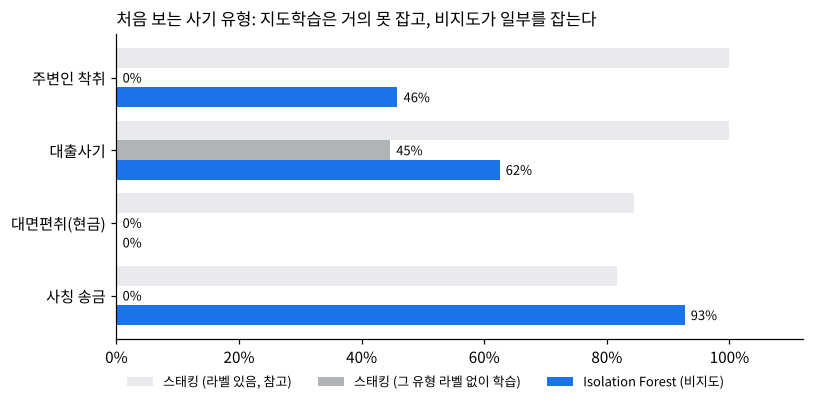

,스태킹 (그 유형 라벨 없이 학습),Isolation Forest (비지도),"스태킹 (라벨 있음, 참고)"
사칭 송금,0.00,0.93,0.82
대면편취(현금),0.00,0.00,0.84
대출사기,0.45,0.62,1.00
주변인 착취,0.00,0.46,1.00


In [9]:
for sc in SC_KO:
    ev[f"s_loso_{sc}"] = oof(hgb_score(F_STACK, exclude=sc))
loso = pd.DataFrame({
    "스태킹 (그 유형 라벨 없이 학습)": {SC_KO[sc]: recall(alerts(f"s_loso_{sc}", B), sc) for sc in SC_KO},
    "Isolation Forest (비지도)": {SC_KO[sc]: recall(alerts("s_iso", B), sc) for sc in SC_KO},
    "스태킹 (라벨 있음, 참고)": {SC_KO[sc]: recall(alerts("s_stack", B), sc) for sc in SC_KO},
})
fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(loso)); h = 0.27
ax.barh(y + h, loso.iloc[:, 2], h, color="#e8eaed", label=loso.columns[2])
ax.barh(y, loso.iloc[:, 0], h, color=GREY, label=loso.columns[0])
ax.barh(y - h, loso.iloc[:, 1], h, color=BLUE, label=loso.columns[1])
for i in range(len(loso)):
    for j, off in [(0, 0), (1, -h)]:
        v = loso.iloc[i, j]; ax.text(v + 0.01, i + off, f"{v:.0%}", va="center", fontsize=8.5)
ax.set_yticks(y); ax.set_yticklabels(loso.index); ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.set_title("처음 보는 사기 유형: 지도학습은 거의 못 잡고, 비지도가 일부를 잡는다", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.45, -0.08), ncol=3); clean(ax); plt.tight_layout(); plt.show()
loso.round(2)

**이게 이 프로젝트의 핵심 발견이다.** 지도학습 모델은 '라벨에 있던 사기'를 잘 외운다. 그 대신 처음 보는 사칭·착취는 거의 놓친다. 반면 비지도 모델은 사칭 송금처럼 '평소와 확실히 다른' 수법을 라벨 없이도 잡는다.

대면편취(현금)는 두 방식 모두 라벨 없이는 못 잡는다. 명절·경조사 현금 인출(정상)과 겉모습이 거의 같기 때문이다. 이 유형은 결국 라벨(신고 사례)을 빨리 모으는 운영 체계가 답이다.

## 5. 2트랙 알림 설계: 예산을 어떻게 나눌까

알림 예산 일부는 스태킹(아는 사기)에, 나머지는 Isolation Forest(처음 보는 사기)에 배분하고 두 결과를 합친다. 배분 비율을 바꿔가며 두 가지를 같이 본다.

- **아는 사기 탐지율**: 모든 라벨로 학습한 스태킹 + IF
- **처음 보는 사기 탐지율**: 유형별 LOSO 스태킹 + IF, 에피소드 가중 평균

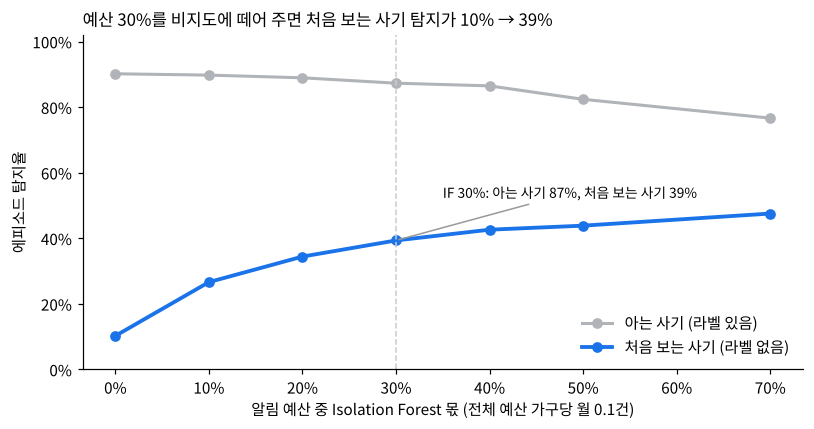

,IF_비중,아는_사기,처음_보는_사기
0,0.0,0.902,0.102
1,0.1,0.898,0.266
2,0.2,0.889,0.344
3,0.3,0.873,0.393
4,0.4,0.865,0.426
5,0.5,0.824,0.439
6,0.7,0.766,0.475


In [10]:
def two_track(stack_col, iso_share, scen=None):
    k_iso = int(B * N_FAM * MONTHS * iso_share)
    a1 = alerts(stack_col, B * (1 - iso_share)) if iso_share < 1 else ev.iloc[:0]
    a2 = ev.nlargest(k_iso, "s_iso") if k_iso else ev.iloc[:0]
    return recall(pd.concat([a1, a2]), scen)

shares = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7]
n_sc = eps.scenario.value_counts()
rows = []
for s in shares:
    known = two_track("s_stack", s)
    unseen = sum(two_track(f"s_loso_{sc}", s, sc) * n_sc[sc] for sc in SC_KO) / n_sc.sum()
    rows.append(dict(IF_비중=s, 아는_사기=known, 처음_보는_사기=unseen))
tt = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(tt.IF_비중, tt.아는_사기, marker="o", color=GREY, lw=2, label="아는 사기 (라벨 있음)")
ax.plot(tt.IF_비중, tt.처음_보는_사기, marker="o", color=BLUE, lw=2.5, label="처음 보는 사기 (라벨 없음)")
pick = 0.3
p = tt.set_index("IF_비중").loc[pick]
ax.axvline(pick, color="#ccc", ls="--", lw=1)
ax.annotate(f"IF 30%: 아는 사기 {p.아는_사기:.0%}, 처음 보는 사기 {p.처음_보는_사기:.0%}",
            xy=(pick, p.처음_보는_사기), xytext=(pick + 0.05, p.처음_보는_사기 + 0.13), fontsize=9,
            arrowprops=dict(arrowstyle="-", color="#999"))
ax.set_ylim(0, 1.02); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.set_xlabel("알림 예산 중 Isolation Forest 몫 (전체 예산 가구당 월 0.1건)"); ax.set_ylabel("에피소드 탐지율")
t0 = tt.set_index("IF_비중").loc[0]
ax.set_title(f"예산 30%를 비지도에 떼어 주면 처음 보는 사기 탐지가 {t0.처음_보는_사기:.0%} → {p.처음_보는_사기:.0%}", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right"); clean(ax); plt.tight_layout(); plt.show()
tt.round(3)

비지도 몫을 늘리면 처음 보는 사기 탐지는 오르고, 아는 사기 탐지는 거의 그대로이거나 조금 내려간다. 이 데이터에서는 **30% 안팎**이 균형점이다. 실제 운영에서는 출시 초기(라벨 거의 없음)에 비지도 비중을 높게 두고, 신고 라벨이 쌓일수록 줄이는 식으로 조정한다.

## 6. 언제 잡느냐: 대응 지연과 피해 차단액

첫 알림 후 가족이 지연 시간 L 안에 대응해 남은 사기 출금을 막는다고 가정한다. 마이데이터 정기 전송은 **기본 주 1회**라서, B2C 앱만으로는 실시간 차단이 어렵다.

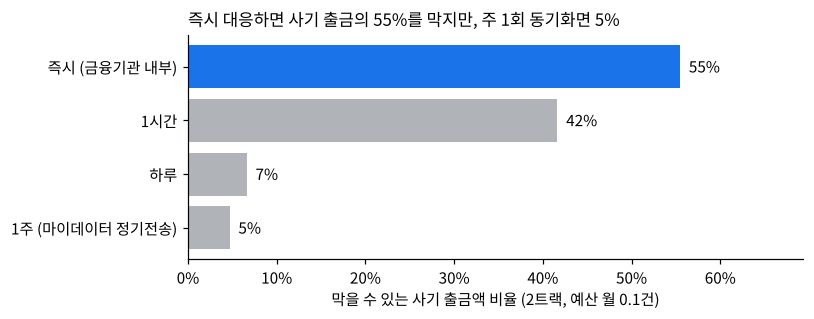

In [11]:
out_fraud = ev[(ev.is_fraud == 1) & (ev.type != "loan_in")]
def prevented_share(al, lag_h):
    first = al[al.is_fraud == 1].groupby("episode").ts.min()
    x = out_fraud.join(first.rename("first_alert"), on="episode")
    return x[x.ts > x.first_alert + pd.Timedelta(hours=lag_h)].amount.sum() / out_fraud.amount.sum()

k_iso = int(B * N_FAM * MONTHS * 0.3)
al_2t = pd.concat([alerts("s_stack", B * 0.7), ev.nlargest(k_iso, "s_iso")])
lags = {"즉시 (금융기관 내부)": 0, "1시간": 1, "하루": 24, "1주 (마이데이터 정기전송)": 168}
prev = pd.Series({k: prevented_share(al_2t, h) for k, h in lags.items()})
fig, ax = plt.subplots(figsize=(7.5, 3.0))
bars = ax.barh(prev.index[::-1], prev.values[::-1], color=[GREY, GREY, GREY, BLUE])
for b_, v in zip(bars, prev.values[::-1]):
    ax.text(v + 0.01, b_.get_y() + b_.get_height()/2, f"{v:.0%}", va="center", fontsize=10)
ax.set_xlim(0, max(prev) * 1.25); ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.set_title(f"즉시 대응하면 사기 출금의 {prev.iloc[0]:.0%}를 막지만, 주 1회 동기화면 {prev.iloc[-1]:.0%}", loc="left", fontsize=11)
ax.set_xlabel("막을 수 있는 사기 출금액 비율 (2트랙, 예산 월 0.1건)")
clean(ax); plt.tight_layout(); plt.show()

## 7. 현실 발생률로 보정한 정밀도

이 데이터는 사기 가구를 6%로 부풀렸다. 실제 고령 가구 중 1년에 금융사기를 당하는 비율은 그보다 훨씬 낮다. 여기서는 **연 0.5%로 가정**한다(공식 통계로 확인 필요). 사기 거래에 가중치 w = (0.5% × 9/12) ÷ 6%를 곱해 정밀도를 다시 계산한다.

가족 입장에서 중요한 질문은 두 가지다. **"알림이 오면 진짜일 확률"**, 그리고 **"헛알림을 몇 달에 한 번 받나"**.

In [12]:
fraud_fam_share = eps.pid.nunique() / N_FAM
REAL = 0.005 * MONTHS / 12
w = REAL / fraud_fam_share
rows = []
for b in [0.02, 0.05, 0.1, 0.2]:
    k_iso = int(b * N_FAM * MONTHS * 0.3)
    al = pd.concat([alerts("s_stack", b * 0.7), ev.nlargest(k_iso, "s_iso")]).drop_duplicates()
    tp, fp = al.is_fraud.sum(), (1 - al.is_fraud).sum()
    rows.append({"예산(가구당 월)": b, "탐지율": recall(al),
                 "정밀도(데이터 그대로)": tp / (tp + fp), "정밀도(현실 보정)": tp * w / (tp * w + fp),
                 "헛알림 주기(개월)": N_FAM * MONTHS / fp})
pr = pd.DataFrame(rows).set_index("예산(가구당 월)")
pr.style.format({"탐지율": "{:.0%}", "정밀도(데이터 그대로)": "{:.1%}", "정밀도(현실 보정)": "{:.2%}", "헛알림 주기(개월)": "{:.0f}"})

,탐지율,정밀도(데이터 그대로),정밀도(현실 보정),헛알림 주기(개월)
예산(가구당 월),,,,
0.020000,41%,44.9%,4.78%,92
0.050000,71%,30.4%,2.62%,30
0.100000,87%,19.5%,1.46%,14
0.200000,94%,11.8%,0.82%,6


현실 보정 정밀도는 낮다. 알림 대부분은 헛알림이라는 뜻이다. 대신 예산 월 0.1건이면 한 가구가 헛알림을 받는 건 **1년 남짓에 한 번**이다. 예산을 월 0.02건까지 줄이면 헛알림은 몇 년에 한 번이 되지만, 탐지율이 절반 아래로 떨어진다. 이 숫자가 제품 설계를 정한다.

- 알림 문구는 "사기입니다"가 아니라 **"평소와 다른 거래가 있어요, 한 번 확인해 보세요"**여야 한다.
- 알림마다 **왜 떴는지**(8장)를 보여줘야 자녀가 10초 안에 판단하고, 앱을 신뢰한다.
- 금융기관 B2B에서는 이 정밀도가 그대로 '상담원 확인 업무량'이 된다. 그래서 기관용 임계값은 따로 잡아야 한다.

## 8. 알림 사유: 자녀에게 보낼 문구

모델 점수만으로는 자녀가 판단할 수 없다. 그래서 알림이 뜬 거래의 피처 값으로 사람이 읽을 수 있는 사유를 만든다. 이 사유가 곧 앱의 알림 문구다.

In [13]:
TYPE_KO = {"transfer_out": "송금", "atm": "현금 인출", "card": "카드 결제", "loan_in": "대출 입금", "bill": "자동이체"}

# 그 수취인에게 처음 보낸 시점부터 몇 시간 지났는지 (사유 문구용)
first_pay = ev[ev.type == "transfer_out"].groupby(["pid", "payee"]).ts.min().rename("payee_first")

def reasons(r):
    out = []
    age_h = (r.ts - r.payee_first).total_seconds() / 3600 if r.type == "transfer_out" else np.nan
    if r.loan_48h and r.type != "loan_in": out.append("대출이 들어온 지 이틀 안에 돈이 빠져나감")
    if r.type == "loan_in": out.append("비대면 대출 입금")
    if r.new_payee: out.append("처음 보는 계좌로 송금")
    if r.z_type > 2.5 and r.past_mean == r.past_mean:
        out.append(f"평소 {TYPE_KO.get(r.type, r.type)} 금액의 약 {r.amount / np.expm1(r.past_mean):.0f}배")
    if r.type == "atm" and r.n_out_24h >= 2: out.append(f"하루 사이 현금 인출 {int(r.n_out_24h) + 1}번째")
    if not r.new_payee and 0 < age_h < 72: out.append(f"{age_h:.0f}시간 전 처음 보낸 계좌로 또 송금")
    elif r.payee_trend > 1.0 and not r.new_payee: out.append("이 계좌로 보내는 돈이 최근 4주 크게 늘어남")
    if r.out_24h_ratio > 15: out.append(f"하루 출금이 평소의 약 {r.out_24h_ratio:.0f}배")
    return " · ".join(out[:2]) or "평소 패턴과 다른 거래"

ex = []
for sc in SC_KO:   # 유형별로 실제 알림이 뜬 사기 거래 하나씩
    hit = al_2t[(al_2t.scenario == sc) & (al_2t.is_fraud == 1)]
    if len(hit): ex.append(hit.sort_values("ts").iloc[0].to_dict() | {"구분": SC_KO[sc]})
for r in al_2t[al_2t.is_fraud == 0].head(2).to_dict("records"):   # 헛알림 예시
    ex.append(r | {"구분": "헛알림(정상 거래)"})
ex = pd.DataFrame(ex).join(first_pay, on=["pid", "payee"])
ex["거래"] = ex.type.map(TYPE_KO) + " " + (ex.amount / 10_000).round().astype(int).astype(str) + "만 원"
ex["알림 사유"] = [reasons(r) for r in ex.itertuples()]
pd.set_option("display.max_colwidth", 80)
ex[["구분", "거래", "알림 사유"]]

,구분,거래,알림 사유
0,사칭 송금,송금 86만 원,1시간 전 처음 보낸 계좌로 또 송금 · 하루 출금이 평소의 약 29배
1,대면편취(현금),현금 인출 131만 원,평소 현금 인출 금액의 약 5배 · 하루 출금이 평소의 약 29배
2,대출사기,대출 입금 500만 원,비대면 대출 입금
3,주변인 착취,송금 27만 원,이 계좌로 보내는 돈이 최근 4주 크게 늘어남
4,헛알림(정상 거래),송금 70만 원,이 계좌로 보내는 돈이 최근 4주 크게 늘어남
5,헛알림(정상 거래),송금 4만 원,평소 패턴과 다른 거래


## 9. 무엇이 판단을 이끄나 (스태킹, 순열 중요도)

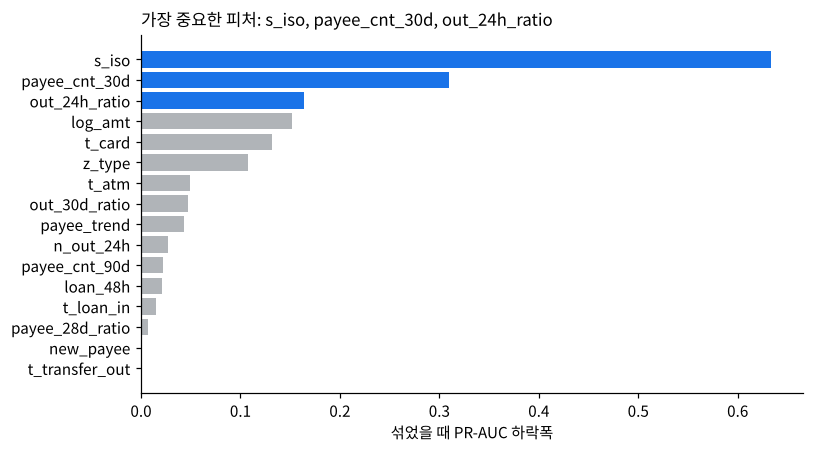

In [14]:
a, b = folds[-1]
tr, te = ev.iloc[a], ev.iloc[b]
m = HistGradientBoostingClassifier(random_state=0, **HGB).fit(tr[F_STACK], tr.is_fraud)
samp = pd.concat([te[te.is_fraud == 1], te[te.is_fraud == 0].sample(20_000, random_state=0)])
pi = permutation_importance(m, samp[F_STACK], samp.is_fraud, scoring="average_precision", n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=F_STACK).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(imp.index, imp.values, color=[BLUE if i >= len(imp) - 3 else GREY for i in range(len(imp))])
ax.set_title(f"가장 중요한 피처: {imp.index[-1]}, {imp.index[-2]}, {imp.index[-3]}", loc="left", fontsize=11)
ax.set_xlabel("섞었을 때 PR-AUC 하락폭"); clean(ax); plt.tight_layout(); plt.show()

## 10. 한계와 다음 단계

**한계**

- 가상 데이터다. 사기 시나리오를 직접 설계했으므로 모델이 '설계자의 가정'을 배운 것일 수 있다. 특히 LOSO에서 비지도가 사칭을 잘 잡은 것은 사칭을 '새 계좌 + 큰 금액'으로 설계했기 때문이기도 하다.
- 연 0.5% 발생률은 가정값이다.
- 거래 단위 점수만 쓴다. 가구 단위 상태(최근 한 달 위험도 누적)는 아직 없다.

**다음 단계**

1. **공개 데이터 검증**: Kaggle PaySim, IEEE-CIS Fraud에 같은 파이프라인(가구 단위 CV, 알림 예산 평가, LOSO)을 적용한다.
2. **대면편취 대응**: 현금 인출의 '시간대·장소 변화'(평소와 다른 지점), 인출 직전 통화 같은 비거래 신호를 검토한다.
3. **가구 단위 위험 점수**: 거래 점수를 가구별로 누적해 '이번 달 주의 가구' 리스트를 만든다. 금융기관 B2B 상담 업무에 맞는 형태다.
4. **라벨 피드백 루프**: 자녀가 알림에 '정상/의심'을 누르면 그게 라벨이 된다. 이 루프가 대면편취 같은 유형의 유일한 해법이다.